# Procesamiento Digital de Imágenes con Python
## Universidad Católica del Norte
## Por: Carlos Menacho
## Cuaderno: Convolución, Filtros y Derivadas

Contenido:
1. **Convolución**: la operación base; cómo se calcula y cómo la hace OpenCV.
2. **Filtros**: suavizado (promedio, gaussiano, mediana, bilateral) y realce (nitidez).
3. **Derivadas**: detección de bordes con Sobel, Laplaciano y Canny.

> 💡 **Idea que une todo el cuaderno:** un filtro lineal es un **sistema LTI en 2D**. Su "respuesta al impulso" es una matriz pequeña llamada **kernel** (o máscara), y la salida se obtiene **convolucionando** la imagen con ese kernel, igual que $y[n] = x[n] * h[n]$ en Señales y Sistemas.

⚠️ Ejecuta primero la **sección 0**. Después, cada tema se puede ejecutar por separado.

## 0. Configuración

Si estás en Google Colab, las librerías ya vienen instaladas. En tu computadora, ejecuta la siguiente celda una sola vez.

In [1]:
%pip install numpy matplotlib opencv-python scikit-image

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["figure.figsize"] = (10, 4)
np.set_printoptions(linewidth=120, suppress=True)

# Imágenes de prueba
camara = data.camera()        # escala de grises, 512x512, uint8
astronauta = data.astronaut()  # color RGB, 512x512x3, uint8

print("OpenCV:", cv2.__version__, "| cámara:", camara.shape, camara.dtype)

OpenCV: 5.0.0 | cámara: (512, 512) uint8


In [3]:
def mostrar(imagenes, titulos=None, cmap="gray", vmin=None, vmax=None):
    # Muestra una lista de imágenes en una fila
    if not isinstance(imagenes, (list, tuple)):
        imagenes = [imagenes]
    n = len(imagenes)
    fig, ejes = plt.subplots(1, n, figsize=(4 * n, 4), squeeze=False)
    for i, img in enumerate(imagenes):
        ax = ejes[0, i]
        if img.ndim == 3:
            ax.imshow(img)
        else:
            ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
        if titulos:
            ax.set_title(titulos[i])
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def ver_matriz(matrices, titulos=None, decimales=0):
    # Dibuja matrices pequeñas mostrando el valor numérico de cada celda
    if not isinstance(matrices, (list, tuple)):
        matrices = [matrices]
    n = len(matrices)
    fig, ejes = plt.subplots(1, n, figsize=(3.2 * n, 3.2), squeeze=False)
    for k, M in enumerate(matrices):
        ax = ejes[0, k]
        ax.imshow(M, cmap="gray")
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                v = M[i, j]
                txt = f"{v:.{decimales}f}" if decimales else f"{int(round(float(v)))}"
                # texto blanco en celdas oscuras, negro en claras
                claro = (v - M.min()) > 0.5 * (M.max() - M.min() + 1e-9)
                ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                        color="black" if claro else "white")
        ax.set_xticks([]); ax.set_yticks([])
        if titulos:
            ax.set_title(titulos[k])
    plt.tight_layout()
    plt.show()

---
# Tema 1: Convolución

## 1.1 Primero en 1D (repaso de Señales y Sistemas)

La convolución discreta de una señal $x[n]$ con un sistema de respuesta al impulso $h[n]$ es:

$$
y[n] = \sum_{k} x[k]\, h[n-k]
$$

En la práctica: **se invierte $h$, se desliza sobre $x$ y en cada posición se multiplica y se suma.**

**Ejemplo numérico:** un *promedio móvil* de 3 muestras, $h = [\tfrac13, \tfrac13, \tfrac13]$, aplicado a un pulso:

| $n$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| $x[n]$ | 0 | 0 | 3 | 3 | 3 | 0 | 0 |
| $y[n]$ | 0 | 1 | 2 | 3 | 2 | 1 | 0 |

Por ejemplo, $y[1] = \tfrac13(0 + 0 + 3) = 1$ y $y[3] = \tfrac13(3+3+3) = 3$. Los bordes del pulso se **suavizan**: el promedio móvil es un **filtro paso bajo**.

x = [0. 0. 3. 3. 3. 0. 0.]
y = [0. 1. 2. 3. 2. 1. 0.]


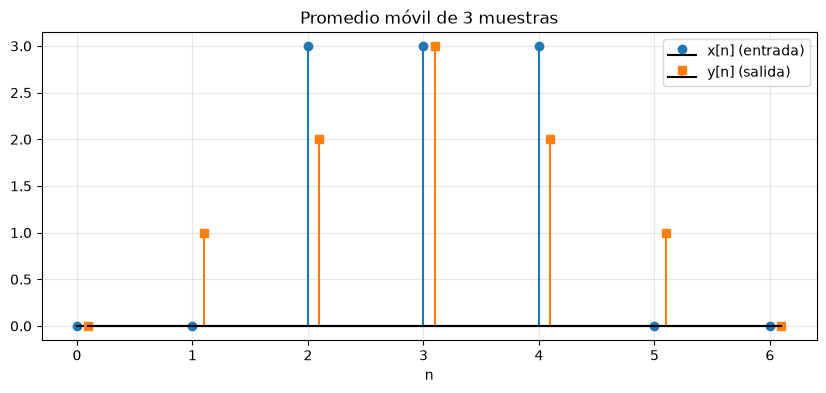

In [4]:
x = np.array([0, 0, 3, 3, 3, 0, 0], dtype=float)
h = np.array([1, 1, 1]) / 3

# 'same': la salida tiene el mismo largo que x


plt.stem(x, linefmt="C0-", markerfmt="C0o", basefmt="k-", label="x[n] (entrada)")
plt.stem(np.arange(len(y)) + 0.1, y, linefmt="C1-", markerfmt="C1s", basefmt="k-", label="y[n] (salida)")
plt.legend(); plt.title("Promedio móvil de 3 muestras"); plt.xlabel("n"); plt.grid(alpha=0.3)
plt.show()

## 1.2 Convolución en 2D

En una imagen hacemos lo mismo, pero el kernel es una **matriz pequeña** (3×3, 5×5, …) que recorre la imagen:

1. Se coloca el centro del kernel sobre un píxel.
2. Se multiplica cada valor del kernel por el píxel que tiene debajo.
3. Se **suman** todos los productos: ese es el nuevo valor del píxel.
4. Se mueve el kernel al siguiente píxel y se repite.

### Ejemplo numérico

Imagen $f$ de 5×5 y kernel promedio de 3×3:

$$
f = \begin{bmatrix}
10 & 10 & 10 & 10 & 10 \\
10 & 20 & 20 & 20 & 10 \\
10 & 20 & \mathbf{90} & 20 & 10 \\
10 & 20 & 20 & 20 & 10 \\
10 & 10 & 10 & 10 & 10
\end{bmatrix}
\qquad
k = \frac{1}{9}\begin{bmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{bmatrix}
$$

**Píxel central (fila 2, columna 2):** el vecindario 3×3 es

$$
\begin{bmatrix} 20 & 20 & 20 \\ 20 & 90 & 20 \\ 20 & 20 & 20 \end{bmatrix}
\;\Rightarrow\; g(2,2) = \frac{8 \cdot 20 + 90}{9} = \frac{250}{9} = 27.8 \approx 28
$$

**Píxel (1, 1):**

$$
\begin{bmatrix} 10 & 10 & 10 \\ 10 & 20 & 20 \\ 10 & 20 & 90 \end{bmatrix}
\;\Rightarrow\; g(1,1) = \frac{200}{9} = 22.2 \approx 22
$$

El valor 90 (un píxel "muy brillante") se **reparte** entre sus vecinos: la imagen se suaviza.

In [5]:
f = np.array([[10, 10, 10, 10, 10],
              [10, 20, 20, 20, 10],
              [10, 20, 90, 20, 10],
              [10, 20, 20, 20, 10],
              [10, 10, 10, 10, 10]], dtype=np.uint8)

k = np.ones((3, 3), dtype=np.float32) / 9     # kernel promedio

# Cálculo "a mano" de un solo píxel: vecindario * kernel, y luego sumar

# filas 1..3, columnas 1..3
vecindario = f[1:4, 1:4].astype(np.float32) 

print("Vecindario del píxel (2,2):\n", )
print("Producto elemento a elemento:\n", )
print("Suma =", )

Vecindario del píxel (2,2):
 [[20. 20. 20.]
 [20. 90. 20.]
 [20. 20. 20.]]
Producto elemento a elemento:
 [[ 2.22  2.22  2.22]
 [ 2.22 10.    2.22]
 [ 2.22  2.22  2.22]]
Suma = 27.777779


### Implementación con bucles (para entender el algoritmo)

¿Qué hacemos con los píxeles del **borde**, donde el kernel "se sale" de la imagen? Hay que **rellenar** (*padding*) la imagen. Aquí usamos el mismo relleno que OpenCV usa por defecto (`BORDER_REFLECT_101`, que refleja la imagen sin repetir el píxel del borde). Lo veremos con más detalle en la sección 1.4.

In [6]:
def correlacion_manual(imagen, kernel):
    # Desliza el kernel sobre la imagen: multiplicar y sumar (igual que cv2.filter2D)

    return salida

g_manual = correlacion_manual(f, k)
print("Resultado manual (sin redondear):\n", np.round(g_manual, 1))

Resultado manual (sin redondear):
 [[14.4 14.4 16.7 14.4 14.4]
 [14.4 22.2 24.4 22.2 14.4]
 [16.7 24.4 27.8 24.4 16.7]
 [14.4 22.2 24.4 22.2 14.4]
 [14.4 14.4 16.7 14.4 14.4]]


## 1.3 Con OpenCV: `cv2.filter2D`

```python
salida = cv2.filter2D(imagen, ddepth, kernel, borderType=cv2.BORDER_REFLECT_101)
```

- `ddepth`: tipo de dato de la salida. `-1` = el mismo de la entrada (`uint8`: se redondea y se satura a 0–255). Con `cv2.CV_32F` o `cv2.CV_64F` se conservan decimales y **valores negativos** (los necesitaremos en derivadas).
- `kernel`: arreglo NumPy de tipo `float32` o `float64`.

cv2.filter2D (uint8):
 [[14 14 17 14 14]
 [14 22 24 22 14]
 [17 24 28 24 17]
 [14 22 24 22 14]
 [14 14 17 14 14]]

¿Igual a nuestra versión manual? True


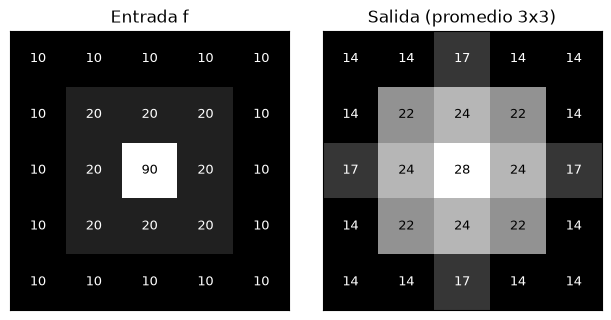

In [7]:
# salida uint8 (redondeada)
            
# salida float (con decimales)
 

print("cv2.filter2D (uint8):\n", g_cv_u8)
print("\n¿Igual a nuestra versión manual?", np.allclose(g_cv_f32, g_manual, atol=1e-4))

ver_matriz([f, g_cv_u8], ["Entrada f", "Salida (promedio 3x3)"])

### ⚠️ `filter2D` hace *correlación*, no convolución

`cv2.filter2D` **no lo invierte**: en realidad calcula la **correlación**.

- Si el kernel es **simétrico** (promedio, gaussiano, Laplaciano…) da exactamente igual.
- Si **no** es simétrico (Sobel, kernels de desplazamiento…) hay que rotarlo con `cv2.flip(kernel, -1)` para obtener la convolución verdadera.

**Experimento:** aplicamos un kernel no simétrico a un **impulso** (imagen de ceros con un 1 en el centro). Recuerda: la convolución con un impulso devuelve la **respuesta al impulso**, es decir, el propio kernel.

Correlación (filter2D directo):
 [[9. 8. 7.]
 [6. 5. 4.]
 [3. 2. 1.]]

Convolución (kernel rotado):
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]


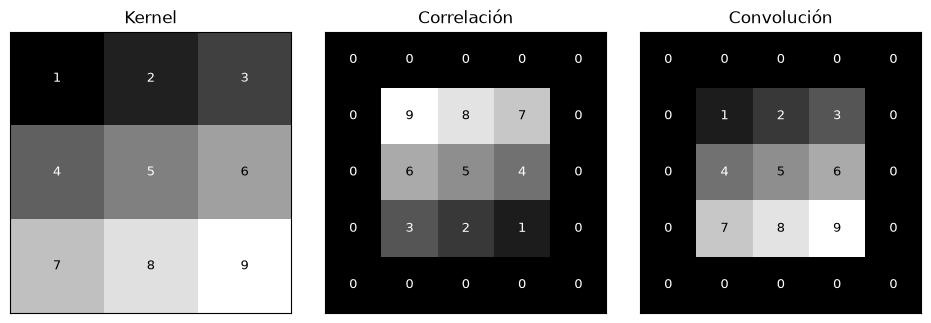

In [8]:
impulso = np.zeros((5, 5), dtype=np.float32)
impulso[2, 2] = 1

kn = np.array([[1, 2, 3],
               [4, 5, 6],
               [7, 8, 9]], dtype=np.float32)

 
# kernel rotado 180°

print("Correlación (filter2D directo):\n", correlacion[1:4, 1:4])
print("\nConvolución (kernel rotado):\n", convolucion[1:4, 1:4])

ver_matriz([kn, correlacion, convolucion], ["Kernel", "Correlación", "Convolución"])

Con la convolución aparece el kernel tal cual (la respuesta al impulso). Con la correlación aparece **rotado 180°**.

## 1.4 Tratamiento de bordes

`cv2.copyMakeBorder` permite ver cómo se rellena la imagen con cada opción. Probemos con una fila `[1 2 3 4 5]` y 2 píxeles de relleno a cada lado:

In [9]:
fila = np.array([[1, 2, 3, 4, 5]], dtype=np.uint8)

tipos = {
    "BORDER_CONSTANT (ceros)": cv2.BORDER_CONSTANT,
    "BORDER_REPLICATE":        cv2.BORDER_REPLICATE,
    "BORDER_REFLECT":          cv2.BORDER_REFLECT,
    "BORDER_REFLECT_101 (*)":  cv2.BORDER_REFLECT_101,
    "BORDER_WRAP":             cv2.BORDER_WRAP,
}
for nombre, t in tipos.items():
    
    print(f"{nombre:26s}: {relleno.ravel()}")
print("\n(*) opción por defecto en OpenCV")

BORDER_CONSTANT (ceros)   : [0 0 1 2 3 4 5 0 0]
BORDER_REPLICATE          : [1 1 1 2 3 4 5 5 5]
BORDER_REFLECT            : [2 1 1 2 3 4 5 5 4]
BORDER_REFLECT_101 (*)    : [3 2 1 2 3 4 5 4 3]
BORDER_WRAP               : [4 5 1 2 3 4 5 1 2]

(*) opción por defecto en OpenCV


En una imagen grande la diferencia solo se nota en una franja delgada del borde (del ancho de la mitad del kernel). Con kernels grandes sí se nota:

In [ ]:
k_grande = np.ones((41, 41), np.float32) / 41**2
mostrar([cv2.filter2D(camara, -1, k_grande, borderType=cv2.BORDER_CONSTANT),
         cv2.filter2D(camara, -1, k_grande, borderType=cv2.BORDER_REFLECT_101)],
        ["Borde con ceros (marco oscuro)", "Borde reflejado"])

## 1.5 Kernels sencillos para ganar intuición

| Kernel | Efecto |
|---|---|
| Identidad: 1 en el centro, 0 en el resto | La imagen no cambia |
| 1 desplazado del centro | **Desplaza** la imagen |
| Todos los valores iguales, suma = 1 | Promedio → **suaviza** |
| Suma = 0 (valores + y −) | Detecta **cambios** (derivadas) → bordes |

> 📌 **Regla práctica:** la **suma de los coeficientes** del kernel es la *ganancia en DC* del filtro (como $H(0)$ en un filtro analógico). Si suma 1, el brillo promedio se conserva. Si suma 0, las zonas uniformes quedan en 0.

Suma de coeficientes -> identidad: 1.0 | promedio 5x5: 1.0


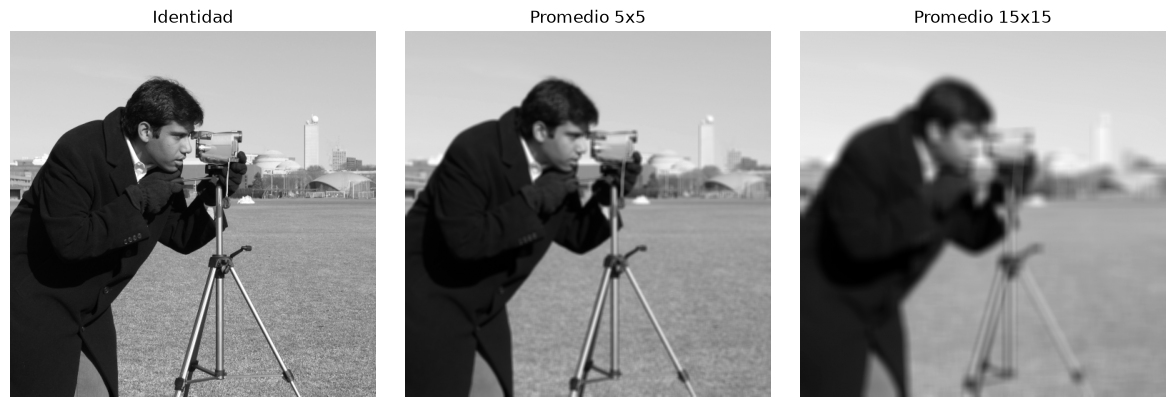

In [10]:
identidad = np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]], np.float32)
promedio5 = np.ones((5, 5), np.float32) / 25
promedio15 = np.ones((15, 15), np.float32) / 225

print("Suma de coeficientes -> identidad:", identidad.sum(), "| promedio 5x5:", promedio5.sum())

mostrar([cv2.filter2D(camara, -1, identidad),
         cv2.filter2D(camara, -1, promedio5),
         cv2.filter2D(camara, -1, promedio15)],
        ["Identidad", "Promedio 5x5", "Promedio 15x15"])

### Ejercicios: Convolución

**Ejercicio 1.1.** Con la imagen $f$ de 5×5 y el kernel promedio 3×3 de la sección 1.2, calcula **a mano** el píxel de la esquina $(0,0)$ usando relleno `BORDER_REFLECT_101`.
*Pista:* usa `cv2.copyMakeBorder(f, 1, 1, 1, 1, cv2.BORDER_REFLECT_101)` para ver la imagen rellena y toma la esquina 3×3. Verifica con `g_cv_u8[0, 0]`.

In [ ]:
f_rellena = cv2.copyMakeBorder(f, 1, 1, 1, 1, cv2.BORDER_REFLECT_101)
print(f_rellena)

# TODO: escribe tu resultado a mano
mi_resultado = None
print("Tu resultado:", mi_resultado, "| OpenCV:", g_cv_u8[0, 0])

**Ejercicio 1.2.** **Predice** qué le pasa a la imagen con cada kernel y luego ejecuta:
- `k_a`: un 1 en la posición (1, 2), es decir, a la derecha del centro.
- `k_b`: la identidad multiplicada por 2.
- `k_c`: la identidad multiplicada por 0.5.

¿Hacia dónde se mueve la imagen con `k_a`? (Recuerda que `filter2D` hace correlación). Para que se note, usa un kernel de 41×41 con el 1 en el extremo derecho.

In [ ]:
k_a = np.zeros((41, 41), np.float32); k_a[20, 40] = 1     # 1 en el extremo derecho
k_b = identidad * 2
k_c = identidad * 0.5

mostrar([camara,
         cv2.filter2D(camara, -1, k_a, borderType=cv2.BORDER_CONSTANT),
         cv2.filter2D(camara, -1, k_b),
         cv2.filter2D(camara, -1, k_c)],
        ["Original", "k_a", "k_b (x2)", "k_c (x0.5)"])

**Ejercicio 1.3.** El kernel promedio 3×3 se puede **separar** en un kernel fila $[1,1,1]/3$ y un kernel columna. Verifica que aplicar ambos 1D, uno tras otro, da el mismo resultado que el 2D. Usa `cv2.sepFilter2D(img, -1, kx, ky)`.
¿Cuántas multiplicaciones por píxel ahorras con un kernel de 15×15? (2D: $15^2$ vs. separable: $2\cdot 15$).

In [ ]:
kx = np.ones(3, np.float32) / 3
ky = np.ones(3, np.float32) / 3

# TODO: aplica cv2.sepFilter2D y compara con cv2.filter2D(camara, cv2.CV_32F, k)
# sep = cv2.sepFilter2D(camara, cv2.CV_32F, kx, ky)
# print("Máxima diferencia:", np.abs(sep - cv2.filter2D(camara, cv2.CV_32F, k)).max())

---
# Tema 2: Filtros

## 2.1 Tipos de filtros

| Filtro | Función OpenCV | Tipo | Bueno para |
|---|---|---|---|
| Promedio (caja) | `cv2.blur` | Lineal, paso bajo | Suavizado rápido |
| Gaussiano | `cv2.GaussianBlur` | Lineal, paso bajo | Suavizado "natural", ruido gaussiano |
| Mediana | `cv2.medianBlur` | **No lineal** | Ruido **sal y pimienta** |
| Bilateral | `cv2.bilateralFilter` | **No lineal** | Suavizar **sin borrar bordes** |
| Nitidez (*sharpening*) | `cv2.filter2D` | Lineal, realce | Resaltar detalles |

> 🔌 **Paso bajo** = deja pasar las variaciones lentas (zonas uniformes) y atenúa las rápidas (detalles finos, ruido, bordes). **Paso alto** = lo contrario.

Para probar los filtros, primero creamos dos imágenes con ruido.

PSNR ruido gaussiano  : 22.4 dB
PSNR sal y pimienta   : 17.8 dB


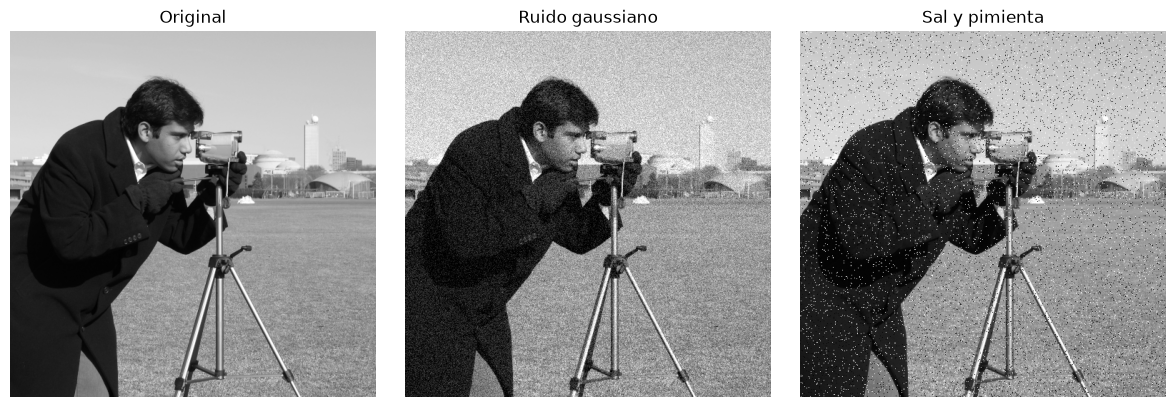

In [11]:
rng = np.random.default_rng(0)

# Ruido gaussiano: a cada píxel se le suma un valor aleatorio N(0, sigma=20)
ruido = rng.normal(0, 20, camara.shape)
ruido_gauss = np.clip(camara + ruido, 0, 255).astype(np.uint8)

# Ruido sal y pimienta: 5% de los píxeles se vuelven negros (0) o blancos (255)
sal_pimienta = camara.copy()
azar = rng.random(camara.shape)
sal_pimienta[azar < 0.025] = 0
sal_pimienta[azar > 0.975] = 255

# PSNR: mide qué tan parecida es una imagen a la original (en dB, mayor = mejor)
print(f"PSNR ruido gaussiano  : {cv2.PSNR(camara, ruido_gauss):.1f} dB")
print(f"PSNR sal y pimienta   : {cv2.PSNR(camara, sal_pimienta):.1f} dB")

mostrar([camara, ruido_gauss, sal_pimienta], ["Original", "Ruido gaussiano", "Sal y pimienta"])

> 📌 **PSNR** (*Peak Signal-to-Noise Ratio*) es una relación señal a ruido, igual que en comunicaciones: $\text{PSNR} = 10\log_{10}\!\left(\frac{255^2}{\text{MSE}}\right)$ dB. Valores típicos: < 20 dB mala, 25–30 dB aceptable, > 35 dB muy buena.

## 2.2 Filtro promedio: `cv2.blur`

```python
salida = cv2.blur(imagen, (ancho, alto))
```

Equivale a `filter2D` con un kernel de unos dividido entre el número de elementos. Cuanto **más grande** el kernel, **más suavizado**, pero también más borrosos quedan los bordes.

Promedio 3x3: PSNR = 27.4 dB
Promedio 5x5: PSNR = 26.2 dB
Promedio 9x9: PSNR = 23.8 dB


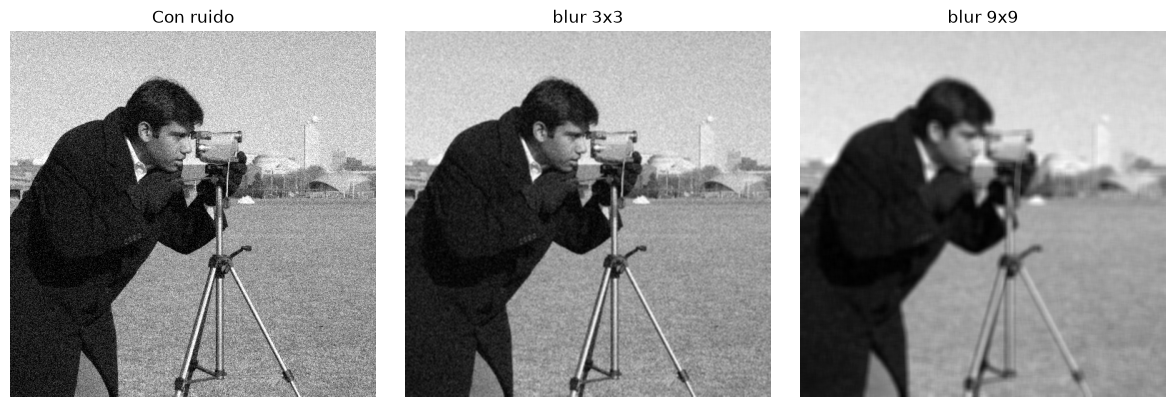

In [12]:
for t in (3, 5, 9):
    print(f"Promedio {t}x{t}: PSNR = ---- dB")

mostrar([ruido_gauss, cv2.blur(ruido_gauss, (3, 3)), cv2.blur(ruido_gauss, (9, 9))],
        ["Con ruido", "blur 3x3", "blur 9x9"])

## 2.3 Filtro gaussiano: `cv2.GaussianBlur`

El kernel sigue la forma de una **campana de Gauss**: el píxel central pesa más y los vecinos lejanos pesan menos. Se ve más natural que el promedio.

```python
salida = cv2.GaussianBlur(imagen, (ancho, alto), sigmaX)
```

- `(ancho, alto)`: tamaño del kernel; deben ser **impares**.
- `sigmaX`: desviación estándar; controla cuánto se suaviza. Si pones `0`, OpenCV la calcula a partir del tamaño.

### Ejemplo numérico: ¿cómo es el kernel?

Kernel gaussiano 1D (sigma=1):
 [0.0545 0.2442 0.4026 0.2442 0.0545]

Kernel 2D (x 1000 para leerlo mejor):
 [[  3  13  22  13   3]
 [ 13  60  98  60  13]
 [ 22  98 162  98  22]
 [ 13  60  98  60  13]
 [  3  13  22  13   3]]

Suma de coeficientes: 1.0


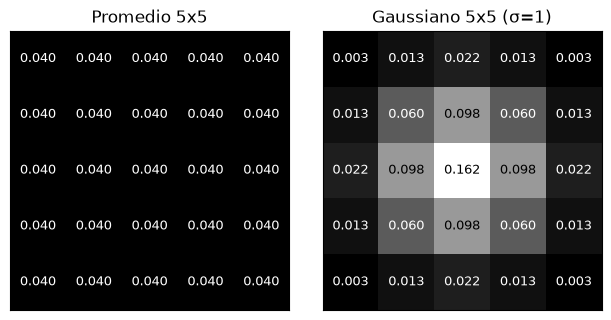

In [13]:
g1d =       # kernel 1D (5x1)
g2d =                           # kernel 2D = columna x fila (es separable)

print("Kernel gaussiano 1D (sigma=1):\n", np.round(g1d.ravel(), 4))
print("\nKernel 2D (x 1000 para leerlo mejor):\n", np.round(g2d * 1000).astype(int))
print("\nSuma de coeficientes:", round(g2d.sum(), 6))

ver_matriz([np.ones((5, 5)) / 25, g2d], ["Promedio 5x5", "Gaussiano 5x5 (σ=1)"], decimales=3)

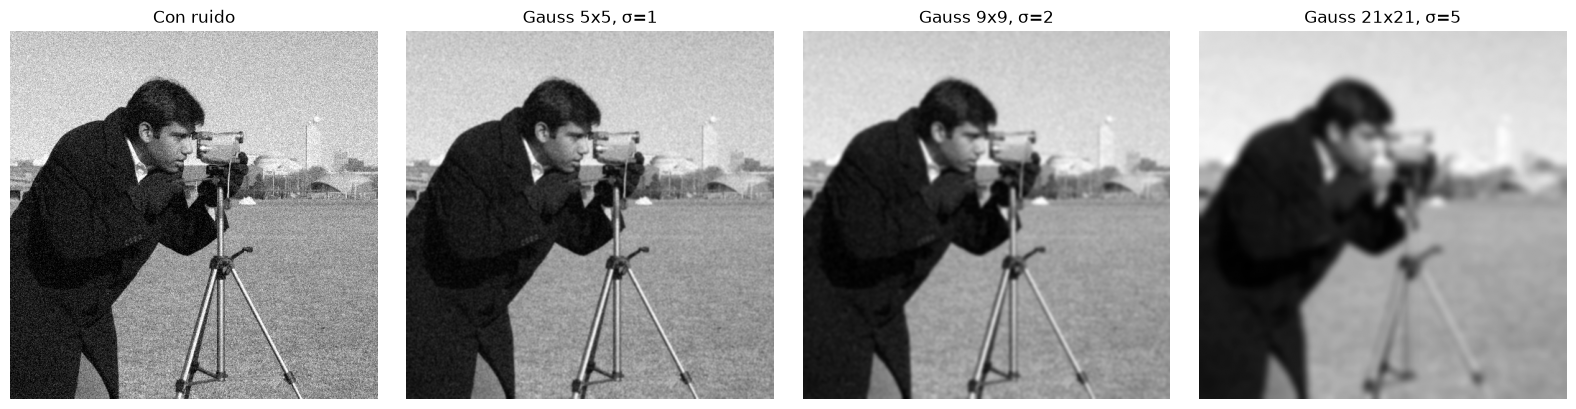

In [14]:
mostrar([ruido_gauss,
         ---
        ["Con ruido", "Gauss 5x5, σ=1", "Gauss 9x9, σ=2", "Gauss 21x21, σ=5"])

## 2.4 Filtro de mediana: `cv2.medianBlur`

**No** es una convolución. Para cada píxel:
1. Toma los valores del vecindario.
2. Los **ordena**.
3. Se queda con el valor **del medio**.

### Ejemplo numérico

Vecindario 3×3 con un píxel de "sal" (255):

$$
\begin{bmatrix} 20 & 22 & 21 \\ 19 & \mathbf{255} & 20 \\ 21 & 20 & 22 \end{bmatrix}
$$

- **Promedio:** $(20+22+21+19+255+20+21+20+22)/9 = 420/9 \approx 47$. El 255 "contamina" el resultado.
- **Mediana:** ordenados → $19, 20, 20, 20, \mathbf{21}, 21, 22, 22, 255$ → **21**. El 255 se ignora por completo.

Por eso la mediana es la mejor opción contra el ruido **sal y pimienta** (valores extremos aislados).

In [15]:
v = np.array([[20, 22, 21],
              [19, 255, 20],
              [21, 20, 22]], dtype=np.uint8)

print("Ordenados:", np.sort(v.ravel()))
print("Promedio :", v.mean().round(1))
print("Mediana  :", np.median(v))

# Verificación con OpenCV (tomamos el píxel central)
print("cv2.blur      ->", cv2.blur(v, (3, 3))[1, 1])
print("cv2.medianBlur->", cv2.medianBlur(v, 3)[1, 1])

Ordenados: [ 19  20  20  20  21  21  22  22 255]
Promedio : 46.7
Mediana  : 21.0
cv2.blur      -> 47
cv2.medianBlur-> 21


Promedio 3x3  : PSNR = 24.9 dB
Gaussiano 3x3 : PSNR = 24.8 dB
Mediana 3x3   : PSNR = 30.1 dB


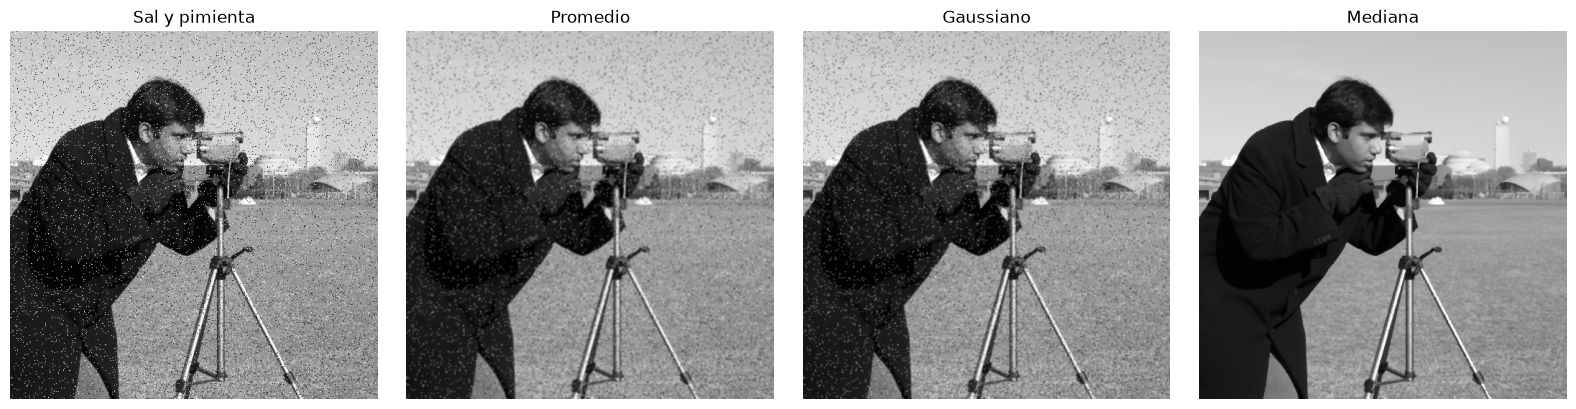

In [16]:
     
# el tamaño es un solo número impar

for nombre, im in [("Promedio 3x3", prom), ("Gaussiano 3x3", gaus), ("Mediana 3x3", medi)]:
    print(f"{nombre:14s}: PSNR = {cv2.PSNR(camara, im):.1f} dB")

mostrar([sal_pimienta, prom, gaus, medi], ["Sal y pimienta", "Promedio", "Gaussiano", "Mediana"])

## 2.5 Filtro bilateral: `cv2.bilateralFilter`

Promedia cada píxel solo con los vecinos que estén **cerca** y que además tengan una intensidad **parecida**. Así suaviza las zonas uniformes pero **no mezcla** los dos lados de un borde.

```python
salida = cv2.bilateralFilter(imagen, d, sigmaColor, sigmaSpace)
```
- `d`: diámetro del vecindario (ej. 9).
- `sigmaColor`: cuánta diferencia de intensidad se considera "parecida" (mayor = suaviza más).
- `sigmaSpace`: cuánto pesan los vecinos según la distancia.

Es más lento que los anteriores.

Gaussiano 9x9: PSNR = 25.8 dB
Bilateral    : PSNR = 27.9 dB


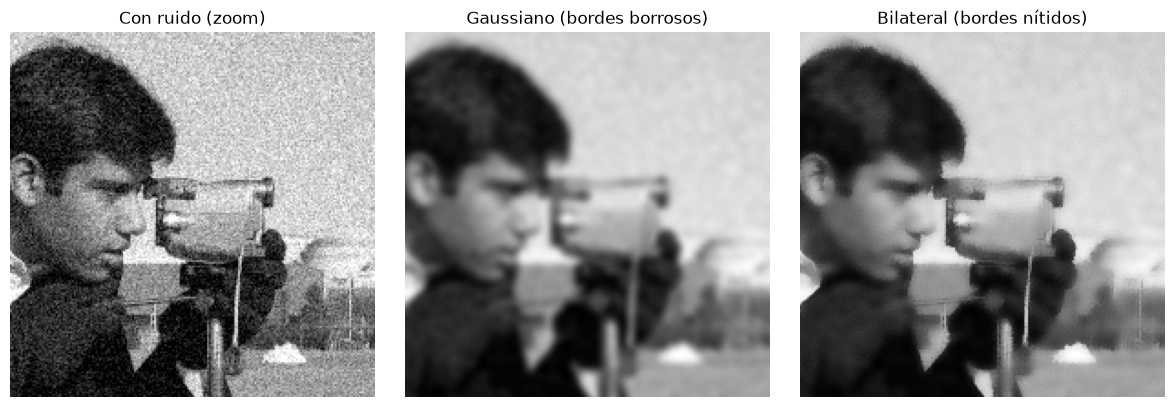

In [17]:


print(f"Gaussiano 9x9: PSNR = {cv2.PSNR(camara, gauss9):.1f} dB")
print(f"Bilateral    : PSNR = {cv2.PSNR(camara, bilat):.1f} dB")

# Acercamiento a una zona con bordes (la cámara y el trípode)
zona = (slice(60, 260), slice(180, 380))
mostrar([ruido_gauss[zona], gauss9[zona], bilat[zona]],
        ["Con ruido (zoom)", "Gaussiano (bordes borrosos)", "Bilateral (bordes nítidos)"])

## 2.6 Filtros de realce (nitidez)

Para hacer una imagen más **nítida** se suman a la imagen original sus **detalles** (componentes de alta frecuencia).

### Kernel de nitidez

$$
k_{\text{nitidez}} = \begin{bmatrix} 0 & -1 & 0 \\ -1 & 5 & -1 \\ 0 & -1 & 0 \end{bmatrix}
\quad (\text{suma} = 1)
$$

**Ejemplo numérico** en una zona uniforme (todo 50): $5\cdot 50 - 4\cdot 50 = 50$, no cambia.
En un borde: $\begin{bmatrix} 50 & 50 & 50 \\ 50 & \mathbf{50} & 100 \\ 50 & 50 & 50 \end{bmatrix} \Rightarrow 5\cdot 50 - (50+50+50+100) = 0$. El lado oscuro del borde se vuelve **más oscuro**, y el lado claro, más claro: el borde se acentúa.

### Máscara de desenfoque (*unsharp masking*)

$$
\text{nítida} = \text{original} + a\cdot(\text{original} - \text{suavizada})
$$

Se implementa con `cv2.addWeighted(img1, w1, img2, w2, 0)`, que calcula $w_1\cdot\text{img1} + w_2\cdot\text{img2}$ con saturación.

Píxel central con kernel de nitidez: 0.0


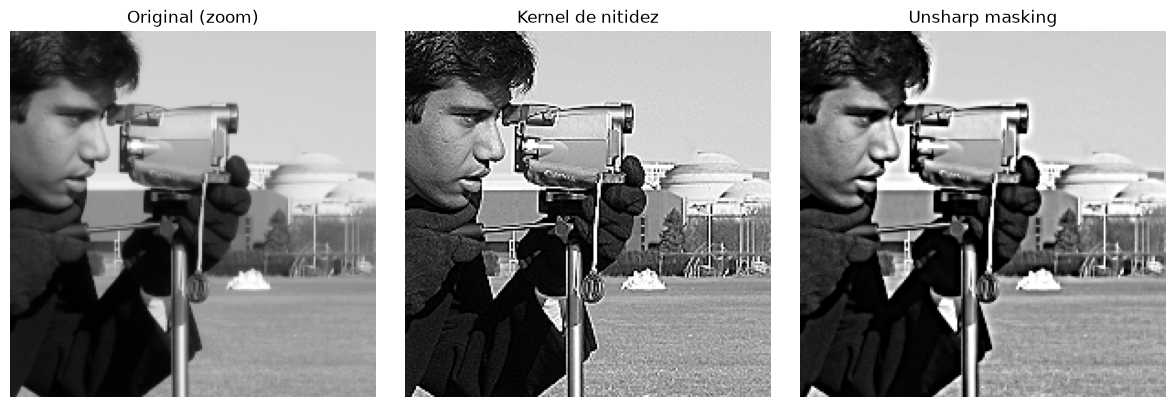

In [18]:
k_nitidez = np.array([[0, -1, 0],
                      [-1, 5, -1],
                      [0, -1, 0]], np.float32)

borde = np.array([[50, 50, 100],
                  [50, 50, 100],
                  [50, 50, 100]], np.uint8)
print("Píxel central con kernel de nitidez:", cv2.filter2D(borde, cv2.CV_32F, k_nitidez)[1, 1])



# Unsharp masking con a = 1.5:  (1 + a)*original - a*suavizad

zona = (slice(100, 300), slice(200, 400))
mostrar([camara[zona], nitida[zona], unsharp[zona]],
        ["Original (zoom)", "Kernel de nitidez", "Unsharp masking"])

### Ejercicios: Filtros

**Ejercicio 2.1.** Calcula a mano el resultado del **promedio** y de la **mediana** 3×3 para este vecindario, y verifica con OpenCV:

$$
\begin{bmatrix} 100 & 0 & 98 \\ 102 & 101 & 0 \\ 99 & 100 & 103 \end{bmatrix}
$$

¿Cuál de los dos valores representa mejor la zona?

In [ ]:
v2 = np.array([[100, 0, 98],
               [102, 101, 0],
               [99, 100, 103]], dtype=np.uint8)

# TODO: escribe tus resultados a mano
promedio_mano = None
mediana_mano = None

print("A mano  -> promedio:", promedio_mano, "| mediana:", mediana_mano)
print("OpenCV  -> promedio:", cv2.blur(v2, (3, 3))[1, 1], "| mediana:", cv2.medianBlur(v2, 3)[1, 1])

**Ejercicio 2.2. Concurso de filtros.** Para cada tipo de ruido, encuentra el filtro y los parámetros que den el **mayor PSNR**. Prueba al menos 3 configuraciones por filtro.

**Predice** primero: ¿qué filtro ganará en cada caso?

In [ ]:
# TODO: agrega más configuraciones
candidatos = {
    "blur 3x3":     lambda im: cv2.blur(im, (3, 3)),
    "Gauss 5x5 σ1": lambda im: cv2.GaussianBlur(im, (5, 5), 1),
    "mediana 3":    lambda im: cv2.medianBlur(im, 3),
    "mediana 5":    lambda im: cv2.medianBlur(im, 5),
    "bilateral":    lambda im: cv2.bilateralFilter(im, 9, 75, 75),
}

for nombre_ruido, im_ruido in [("Gaussiano", ruido_gauss), ("Sal y pimienta", sal_pimienta)]:
    print(f"--- Ruido {nombre_ruido} (sin filtrar: {cv2.PSNR(camara, im_ruido):.1f} dB)")
    for nombre, filtro in candidatos.items():
        print(f"   {nombre:14s}: {cv2.PSNR(camara, filtro(im_ruido)):.1f} dB")

**Ejercicio 2.3.** Aplica la mediana 3×3 **dos veces seguidas** a `sal_pimienta`. ¿Mejora el PSNR respecto a una sola vez? ¿Y respecto a una mediana 5×5? Observa también qué pasa con los detalles finos.

**Ejercicio 2.4.** Aumenta el valor `a` del *unsharp masking* (prueba 0.5, 1.5, 5). ¿Qué aparece alrededor de los bordes cuando `a` es muy grande? (Busca en la imagen "halos" claros y oscuros).

In [ ]:
# TODO 2.3
# una = cv2.medianBlur(sal_pimienta, 3)
# dos = cv2.medianBlur(una, 3)
# cinco = cv2.medianBlur(sal_pimienta, 5)
# ...

# TODO 2.4
# for a in (0.5, 1.5, 5):
#     ...

---
# Tema 3: Derivadas y detección de bordes

## 3.1 Idea

Un **borde** es un lugar donde la intensidad cambia **bruscamente**. La herramienta matemática para medir cambios es la **derivada**.

En imágenes digitales la derivada se aproxima con **diferencias** entre píxeles vecinos:

$$
\frac{\partial f}{\partial x} \approx f(x+1) - f(x)
\qquad\qquad
\frac{\partial^2 f}{\partial x^2} \approx f(x+1) - 2f(x) + f(x-1)
$$

### Ejemplo numérico en 1D (una fila de la imagen)

| $x$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|---|
| $f(x)$ | 10 | 10 | 10 | 10 | 200 | 200 | 200 | 200 |
| $f'(x) = f(x+1)-f(x)$ | 0 | 0 | 0 | **190** | 0 | 0 | 0 | |
| $f''(x)$ | | 0 | 0 | **190** | **−190** | 0 | 0 | |

- **1.ª derivada:** un **pico** justo en el borde → detectamos bordes buscando valores **grandes**.
- **2.ª derivada:** un par positivo/negativo → el borde está donde **cruza por cero**.
- En zonas uniformes ambas derivadas valen **0**.
- ⚠️ Las derivadas pueden ser **negativas** (borde de claro a oscuro). Por eso en OpenCV usaremos `cv2.CV_64F` como tipo de salida.

f   : [ 10.  10.  10.  10. 200. 200. 200. 200.]
f'  : [  0.   0.   0. 190.   0.   0.   0.]
f'' : [   0.    0.  190. -190.    0.    0.]


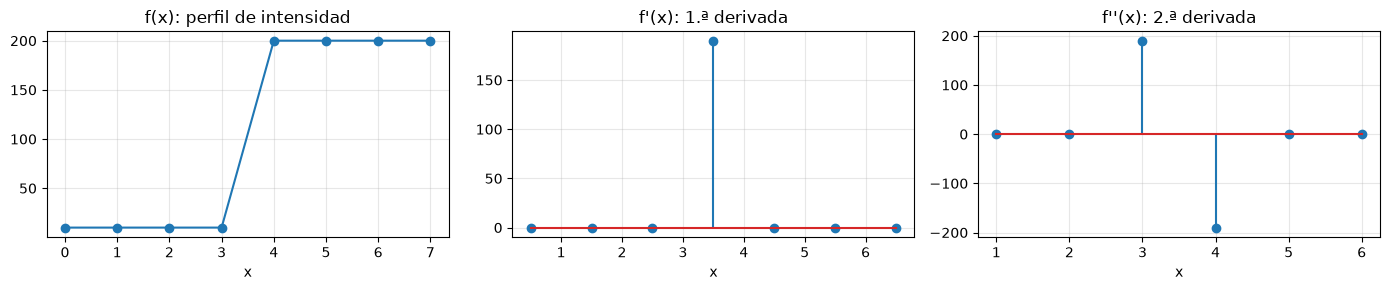

In [19]:
perfil = np.array([10, 10, 10, 10, 200, 200, 200, 200], dtype=float)
# f(x+1) - f(x)

d1 = np.diff(perfil) 

# segunda diferencia
d2 = np.diff(perfil, n=2)     

print("f   :", perfil)
print("f'  :", d1)
print("f'' :", d2)

fig, ax = plt.subplots(1, 3, figsize=(14, 3))
ax[0].plot(perfil, "o-");            ax[0].set_title("f(x): perfil de intensidad")
ax[1].stem(np.arange(len(d1)) + 0.5, d1); ax[1].set_title("f'(x): 1.ª derivada")
ax[2].stem(np.arange(len(d2)) + 1, d2);   ax[2].set_title("f''(x): 2.ª derivada")
for a in ax: a.grid(alpha=0.3); a.set_xlabel("x")
plt.tight_layout(); plt.show()

## 3.2 Kernels de derivada

Una derivada es una **convolución** con un kernel cuyos coeficientes **suman 0**:

| Nombre | Kernel horizontal ($\partial/\partial x$) | Comentario |
|---|---|---|
| Diferencia central | $[-1\;\;0\;\;1]$ | Muy sensible al ruido |
| **Sobel** | $\begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}$ | Deriva en $x$ y **suaviza** en $y$ (más robusto) |
| Scharr | $\begin{bmatrix} -3 & 0 & 3 \\ -10 & 0 & 10 \\ -3 & 0 & 3 \end{bmatrix}$ | Más preciso en la dirección del borde |
| **Laplaciano** | $\begin{bmatrix} 0 & 1 & 0 \\ 1 & -4 & 1 \\ 0 & 1 & 0 \end{bmatrix}$ | 2.ª derivada en $x$ **y** $y$ a la vez |

El kernel vertical ($\partial/\partial y$) de Sobel es el horizontal **transpuesto**.

## 3.3 Sobel con OpenCV

```python
gx = cv2.Sobel(imagen, cv2.CV_64F, 1, 0, ksize=3)   # derivada en x (dx=1, dy=0)
gy = cv2.Sobel(imagen, cv2.CV_64F, 0, 1, ksize=3)   # derivada en y (dx=0, dy=1)
```

### Ejemplo numérico: borde vertical

Imagen 5×6: izquierda oscura (10), derecha clara (200). En la columna 2 (justo a la izquierda del borde), Sobel $x$ da:

$$
(-1)(10) + (1)(200) + (-2)(10) + (2)(200) + (-1)(10) + (1)(200) = 4\cdot(200-10) = \mathbf{760}
$$

Y en la dirección $y$ no hay cambios, así que $g_y = 0$ en toda la imagen.

Imagen:
 [[ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]
 [ 10  10  10 200 200 200]]

Sobel x:
 [[  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]
 [  0.   0. 760. 760.   0.   0.]]

Sobel y:
 [[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]]


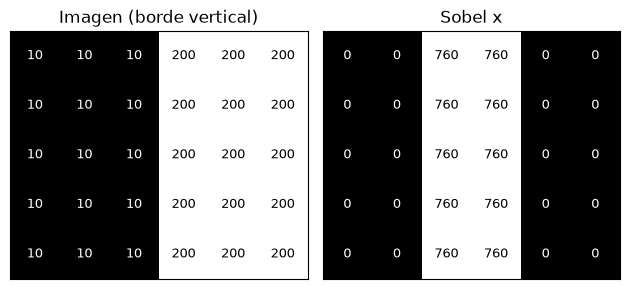

In [20]:
escalon = np.array([[10, 10, 10, 200, 200, 200]] * 5, dtype=np.uint8)



print("Imagen:\n", escalon)
print("\nSobel x:\n", gx)
print("\nSobel y:\n", gy)

ver_matriz([escalon, gx], ["Imagen (borde vertical)", "Sobel x"])

### ¿Por qué `cv2.CV_64F` y no `uint8`?

Si el borde va de **claro a oscuro**, la derivada es **negativa**. Con `uint8` los negativos se saturan a **0** y ese borde **desaparece**.

Rango con CV_8U : 0 a 255
Rango con CV_64F: -1020.0 a 1020.0


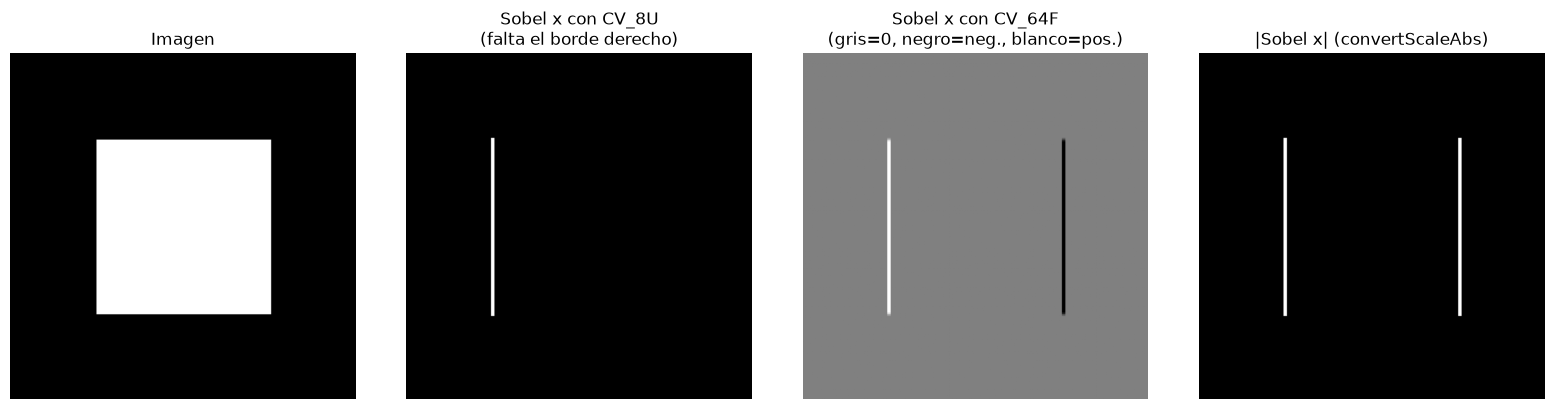

In [21]:
# Imagen sintética: un cuadrado blanco sobre fondo negro
cuadro = np.zeros((200, 200), np.uint8)
cv2.rectangle(cuadro, (50, 50), (150, 150), 255, -1)   # -1 = relleno

gx_u8 = cv2.Sobel(cuadro, cv2.CV_8U, 1, 0, ksize=3)     # ❌ pierde los negativos
gx_64 = cv2.Sobel(cuadro, cv2.CV_64F, 1, 0, ksize=3)    # ✅ conserva el signo

print("Rango con CV_8U :", gx_u8.min(), "a", gx_u8.max())
print("Rango con CV_64F:", gx_64.min(), "a", gx_64.max())

mostrar([cuadro, gx_u8, gx_64, cv2.convertScaleAbs(gx_64)],
        ["Imagen", "Sobel x con CV_8U\n(falta el borde derecho)",
         "Sobel x con CV_64F\n(gris=0, negro=neg., blanco=pos.)", "|Sobel x| (convertScaleAbs)"])

> 📌 `cv2.convertScaleAbs(x)` calcula el **valor absoluto** y lo convierte a `uint8` (con saturación). Es la forma típica de **visualizar** una derivada.

## 3.4 Magnitud y dirección del gradiente

El **gradiente** junta las dos derivadas en un vector $\nabla f = (g_x, g_y)$:

$$
|\nabla f| = \sqrt{g_x^2 + g_y^2} \qquad\qquad \theta = \arctan\!\left(\frac{g_y}{g_x}\right)
$$

- **Magnitud:** qué tan fuerte es el borde. → `cv2.magnitude(gx, gy)`
- **Dirección:** hacia dónde aumenta la intensidad (perpendicular al borde). → `cv2.phase(gx, gy, angleInDegrees=True)`

**Ejemplo numérico:** si en un píxel $g_x = 300$ y $g_y = 400$ → $|\nabla f| = \sqrt{300^2 + 400^2} = 500$ y $\theta = \arctan(400/300) = 53.1°$.

Magnitud : 500.0
Dirección: 53.1 grados


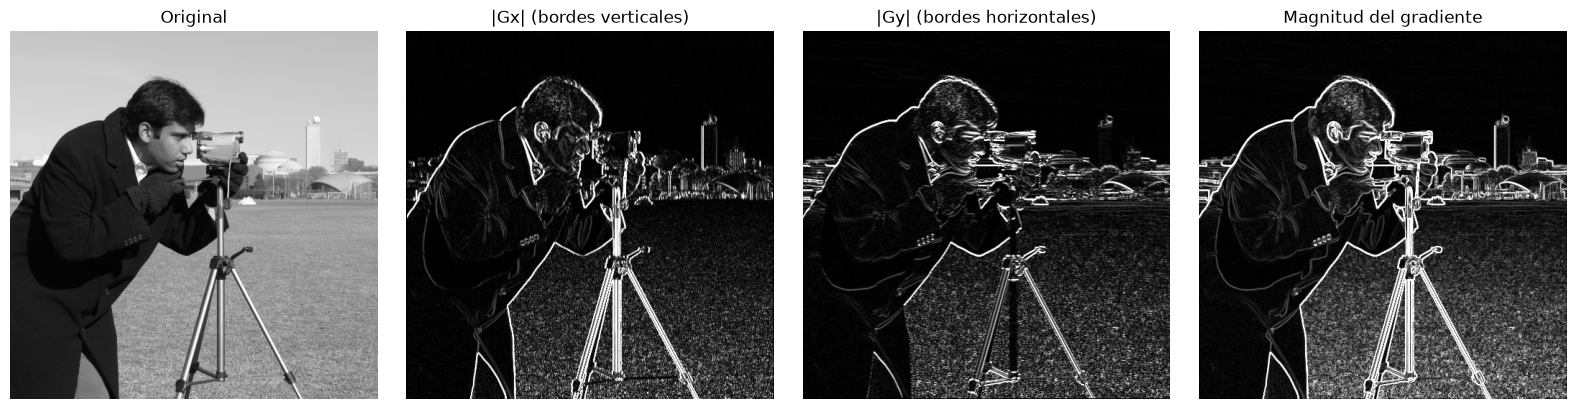

In [22]:
gx_p = np.array([[300.0]]); gy_p = np.array([[400.0]])
print("Magnitud :", cv2.magnitude(gx_p, gy_p)[0, 0])
print("Dirección:", round(cv2.phase(gx_p, gy_p, angleInDegrees=True)[0, 0], 1), "grados")

# Ahora con la imagen real


mostrar([camara, cv2.convertScaleAbs(gx), cv2.convertScaleAbs(gy), cv2.convertScaleAbs(mag)],
        ["Original", "|Gx| (bordes verticales)", "|Gy| (bordes horizontales)", "Magnitud del gradiente"])

### De magnitud a bordes: umbralización

Para obtener una imagen **binaria** de bordes, nos quedamos con los píxeles cuya magnitud supere un umbral:

```python
_, bordes = cv2.threshold(imagen, umbral, 255, cv2.THRESH_BINARY)
```

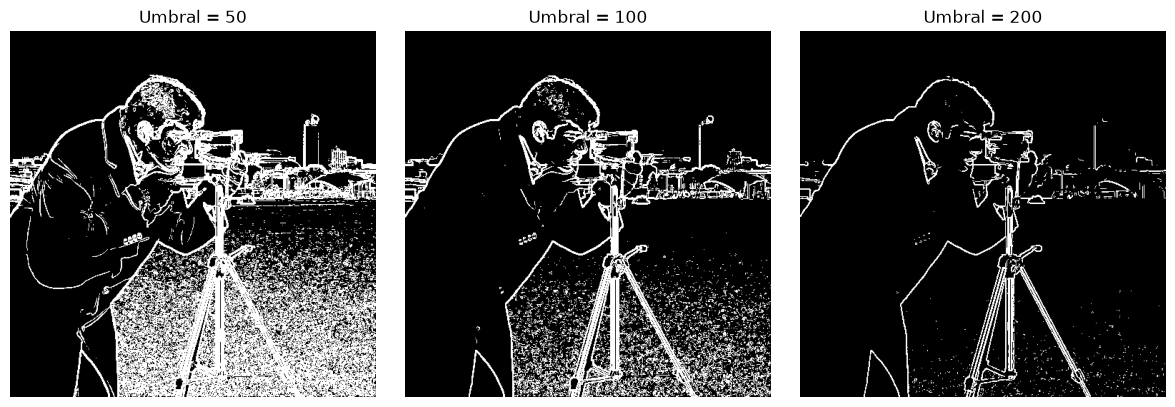

In [23]:

umbrales = (50, 100, 200)
mostrar([cv2.threshold(mag_u8, u, 255, cv2.THRESH_BINARY)[1] for u in umbrales],
        [f"Umbral = {u}" for u in umbrales])

## 3.5 Laplaciano: `cv2.Laplacian`

Es la **segunda derivada** en $x$ y $y$ al mismo tiempo. No necesita dos kernels y responde igual a bordes en cualquier dirección.

**Ejemplo numérico** con el kernel $\begin{bmatrix} 0 & 1 & 0 \\ 1 & -4 & 1 \\ 0 & 1 & 0 \end{bmatrix}$:
- Zona uniforme (todo 50): $4\cdot 50 - 4\cdot 50 = 0$.
- Punto brillante aislado (centro 200, vecinos 50): $4\cdot 50 - 4\cdot 200 = -600$. ¡Respuesta muy fuerte!

⚠️ Al ser una segunda derivada, es **muy sensible al ruido**. Por eso casi siempre se **suaviza primero** con un gaussiano. A esa combinación se le llama **LoG** (*Laplacian of Gaussian*).

Laplaciano del punto aislado: -600.0


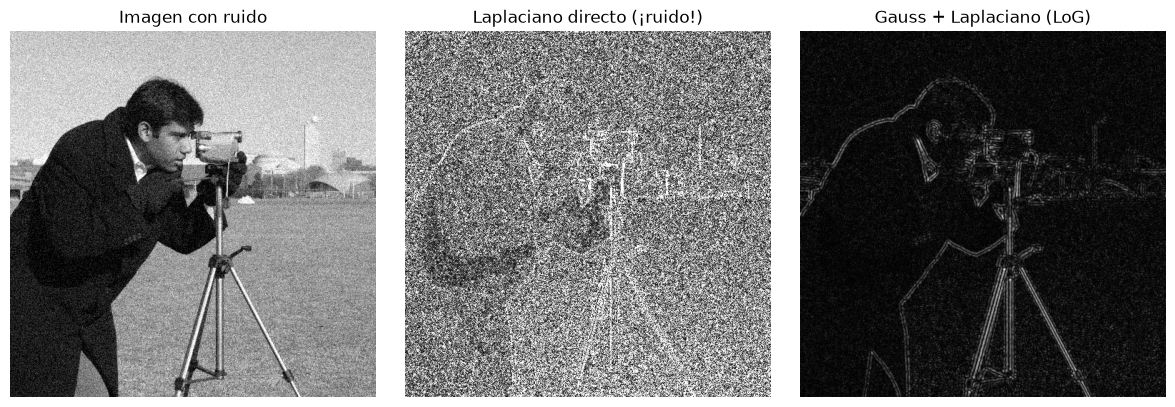

In [24]:
punto = np.full((3, 3), 50, np.uint8); punto[1, 1] = 200
print("Laplaciano del punto aislado:", cv2.Laplacian(punto, cv2.CV_64F, ksize=1)[1, 1])
# (ksize=1 usa exactamente el kernel de la tabla)

lap_directo = cv2.Laplacian(ruido_gauss, cv2.CV_64F, ksize=3)
lap_suave = cv2.Laplacian(cv2.GaussianBlur(ruido_gauss, (5, 5), 1.5), cv2.CV_64F, ksize=3)  # LoG

mostrar([ruido_gauss, cv2.convertScaleAbs(lap_directo), cv2.convertScaleAbs(lap_suave)],
        ["Imagen con ruido", "Laplaciano directo (¡ruido!)", "Gauss + Laplaciano (LoG)"])

## 3.6 Detector de Canny: `cv2.Canny`

Es el detector de bordes más usado. Junta todo lo visto en el cuaderno:

1. **Suavizado gaussiano** → reduce el ruido.
2. **Gradiente con Sobel** → magnitud y dirección.
3. **Supresión de no-máximos** → adelgaza los bordes a 1 píxel de ancho.
4. **Umbral con histéresis** (dos umbrales):
   - Magnitud > `umbral_alto` → borde **seguro**.
   - Magnitud < `umbral_bajo` → **no** es borde.
   - Entre ambos → es borde solo si está **conectado** a un borde seguro.

```python
bordes = cv2.Canny(imagen, umbral_bajo, umbral_alto)
```

> 🔌 La histéresis es la misma idea del **disparador Schmitt**: dos umbrales distintos evitan que el ruido haga "parpadear" la salida.

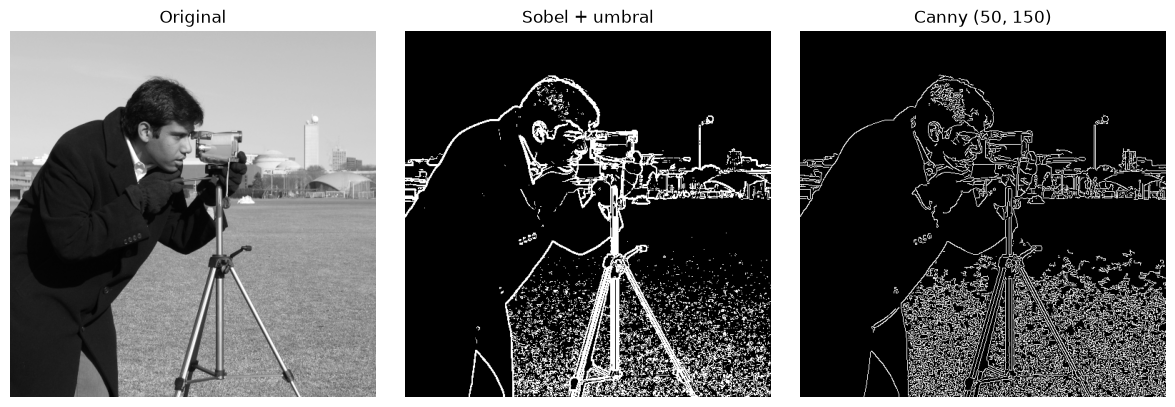

In [25]:
_, sobel_umbral = cv2.threshold(mag_u8, 100, 255, cv2.THRESH_BINARY)


mostrar([camara, sobel_umbral, canny], ["Original", "Sobel + umbral", "Canny (50, 150)"])

### Ejercicios: Derivadas

**Ejercicio 3.1.** Calcula **a mano** las derivadas $f'$ y $f''$ de este perfil y verifica con `np.diff`. ¿Dónde están los bordes? ¿Cuál sube y cuál baja?

$$ f = [50,\;50,\;50,\;150,\;150,\;150,\;20,\;20] $$

In [ ]:
f31 = np.array([50, 50, 50, 150, 150, 150, 20, 20], dtype=float)

# TODO: escribe tus resultados a mano
d1_mano = None
d2_mano = None

print("np.diff  f' :", np.diff(f31))
print("np.diff  f'':", np.diff(f31, n=2))

**Ejercicio 3.2.** Con la imagen `circulo` (un círculo blanco sobre fondo negro), **predice** antes de ejecutar:
1. ¿En qué parte del círculo $g_x$ será **positivo** y en cuál **negativo**?
2. ¿En qué partes del borde $g_x$ será **cero**?
3. ¿Cómo se verá la magnitud?

In [ ]:
circulo = np.zeros((200, 200), np.uint8)
cv2.circle(circulo, (100, 100), 60, 255, -1)

gx_c = cv2.Sobel(circulo, cv2.CV_64F, 1, 0, ksize=3)
gy_c = cv2.Sobel(circulo, cv2.CV_64F, 0, 1, ksize=3)

# En gx y gy: gris = 0, blanco = positivo, negro = negativo
lim = np.abs(gx_c).max()   # escala simétrica para que el 0 quede en gris
mostrar([gx_c, gy_c], ["Gx", "Gy"], vmin=-lim, vmax=lim)
mostrar([circulo, cv2.magnitude(gx_c, gy_c)], ["Círculo", "Magnitud"])

**Ejercicio 3.3.** Ajusta los umbrales de Canny en `camara`. Prueba `(10, 30)`, `(50, 150)` y `(150, 300)`.
- ¿Qué pasa con umbrales muy bajos? ¿Y muy altos?
- Aplica Canny a `ruido_gauss` **sin** suavizar y **con** un `GaussianBlur` previo de 5×5. ¿Cuál da bordes más limpios?

In [ ]:
# TODO
# pares = [(10, 30), (50, 150), (150, 300)]
# mostrar([cv2.Canny(camara, b, a) for b, a in pares], [f"Canny {b}, {a}" for b, a in pares])

**Ejercicio 3.4 (reto).** Implementa Sobel $x$ usando **solo** `cv2.filter2D` con el kernel de la tabla (sección 3.2) y compara con `cv2.Sobel`.
*Cuidado:* ¿necesitas rotar el kernel? (Recuerda la diferencia entre correlación y convolución de la sección 1.3).

In [ ]:
k_sobel_x = np.array([[-1, 0, 1],
                      [-2, 0, 2],
                      [-1, 0, 1]], np.float32)

# TODO
# mi_gx = cv2.filter2D(camara, cv2.CV_64F, k_sobel_x)
# print("Máxima diferencia con cv2.Sobel:", np.abs(mi_gx - cv2.Sobel(camara, cv2.CV_64F, 1, 0, ksize=3)).max())